Training final stacking model on full training data (FAST MODE)...

=== Test Set Performance ===
              precision    recall  f1-score   support

         0.0       0.78      1.00      0.88      7000
         1.0       0.00      0.00      0.00      2000

    accuracy                           0.78      9000
   macro avg       0.39      0.50      0.44      9000
weighted avg       0.60      0.78      0.68      9000

Accuracy:  0.7778
Precision: 0.6049
Recall:    0.7778
F1-score:  0.6806
ROC AUC:   0.6886


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


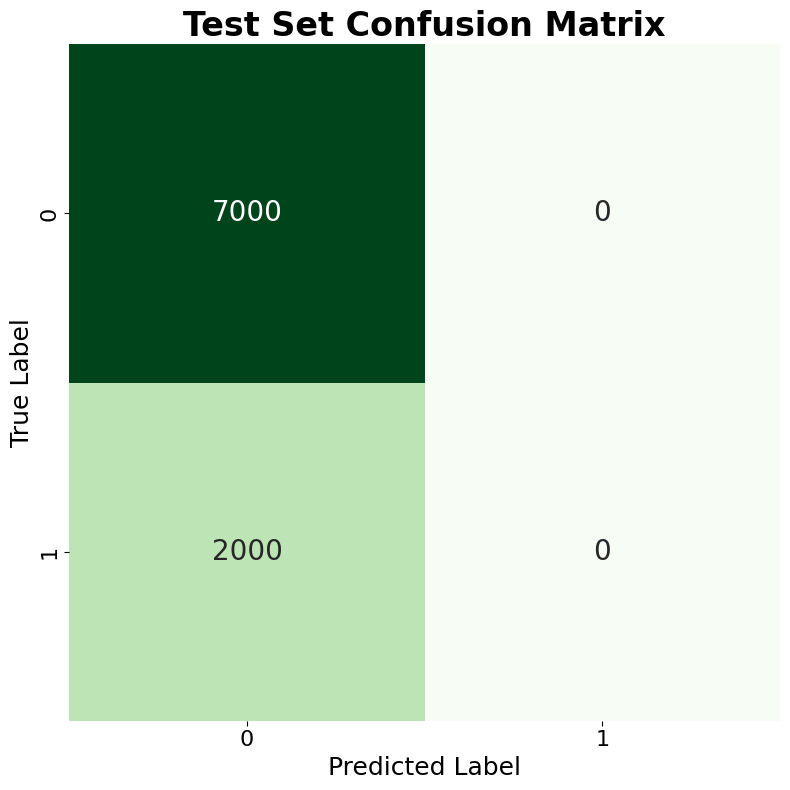

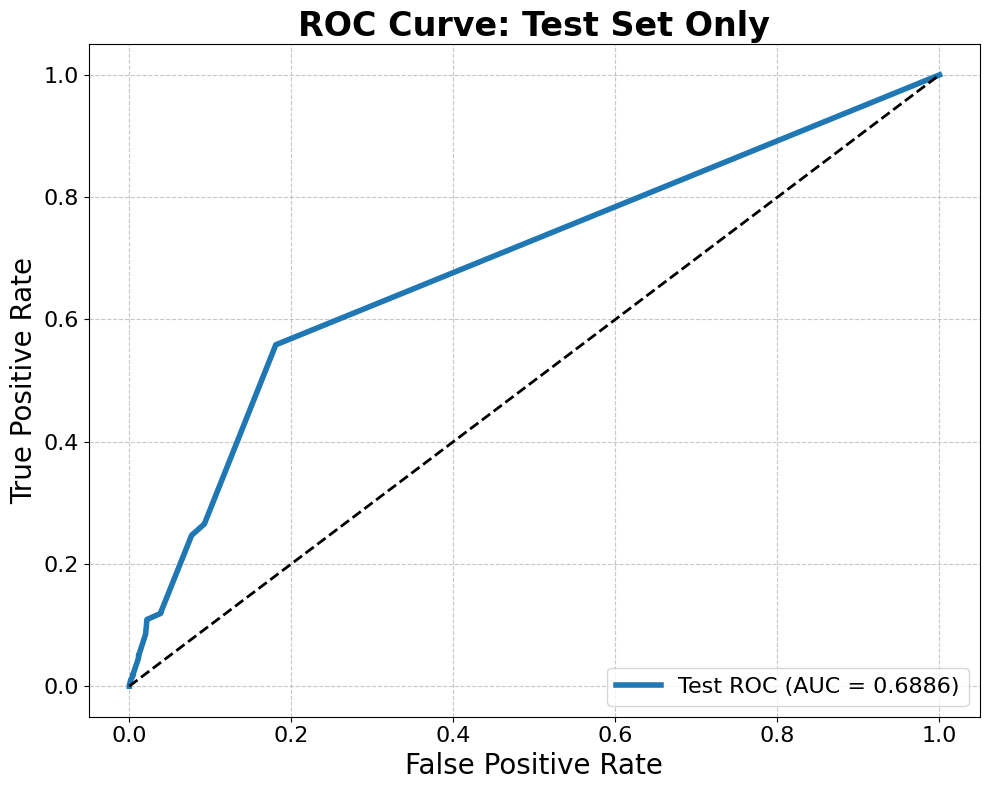


✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_rf_lr.pkl'


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional CPU acceleration (does NOT change model logic)
try:
    from sklearnex import patch_sklearn
    patch_sklearn()
except Exception:
    pass

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             confusion_matrix, roc_curve, auc)
import joblib

# ===============================
# Direct CSV paths (Train & Test)
# ===============================
TRAIN_CSV_PATH = r"/content/train_80_selected_hybrid (1).csv"
TEST_CSV_PATH  = r"/content/test_20_selected_features (1).csv"

TARGET_COLUMN = "loan_status"

train_df = pd.read_csv(TRAIN_CSV_PATH)
test_df  = pd.read_csv(TEST_CSV_PATH)

X_train = train_df.drop(columns=[TARGET_COLUMN])
y_train = train_df[TARGET_COLUMN]

X_test = test_df.drop(columns=[TARGET_COLUMN])
y_test = test_df[TARGET_COLUMN]

# ===============================
# Use your already-found "final" params (fast, no tuning)
# ===============================
final_knn = KNeighborsClassifier(
    weights='uniform',
    p=1,
    n_neighbors=7,
    leaf_size=30,
    algorithm='auto',
    n_jobs=-1
)

final_rf = RandomForestClassifier(
    random_state=42,
    n_estimators=50,
    min_samples_split=5,
    min_samples_leaf=2,
    max_depth=18,
    bootstrap=True,
    n_jobs=-1
)

final_meta_lr = LogisticRegression(
    random_state=42,
    max_iter=1000,
    solver='liblinear',
    penalty='l1',
    C=0.01
)

stacking_final = StackingClassifier(
    estimators=[('knn', final_knn), ('rf', final_rf)],
    final_estimator=final_meta_lr,
    cv=3,
    n_jobs=-1,
    passthrough=False,
    verbose=0
)

print("Training final stacking model on full training data (FAST MODE)...")
stacking_final.fit(X_train, y_train)

# ===============================
# Test evaluation
# ===============================
y_test_pred = stacking_final.predict(X_test)
y_test_prob = stacking_final.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_test_pred)
pre = precision_score(y_test, y_test_pred, average='weighted', zero_division=0)
rec = recall_score(y_test, y_test_pred, average='weighted', zero_division=0)
f1 = f1_score(y_test, y_test_pred, average='weighted', zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_prob)

print("\n=== Test Set Performance ===")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy:  {acc:.4f}")
print(f"Precision: {pre:.4f}")
print(f"Recall:    {rec:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC AUC:   {roc_auc:.4f}")

cm_test = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(8, 8))
sns.heatmap(cm_test, annot=True, fmt='d', cmap='Greens', cbar=False,
            annot_kws={"size": 20})
plt.title('Test Set Confusion Matrix', fontsize=24, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=18)
plt.ylabel('True Label', fontsize=18)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)
plt.figure(figsize=(10, 8))
plt.plot(fpr_test, tpr_test, lw=4, label=f'Test ROC (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlabel('False Positive Rate', fontsize=20)
plt.ylabel('True Positive Rate', fontsize=20)
plt.title('ROC Curve: Test Set Only', fontsize=24, fontweight='bold')
plt.legend(loc='lower right', fontsize=16)
plt.grid(alpha=0.7, linestyle='--')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

joblib.dump(stacking_final, 'stacking_ensemble_knn_rf_lr.pkl')
print("\n✅ Final stacking ensemble model saved as 'stacking_ensemble_knn_rf_lr.pkl'")


fs + ros